# VLA branch · benchmarks & datasets
**Training an affordance-aware VLA: where the training data and the closed-loop tests come from** · 10 Nov 2026

- **Main claim on LIBERO-Plus.** LIBERO-Occ and LIBERO-PRO diagnose specific failures, plain LIBERO is a sanity check, and **RoboTwin 2.0 Hard** is the second benchmark.
- **One LIBERO-Object task file is on the Mac (633 MB, 50 demos).** Proprioception alone gives a contact–approach–waypoint (CAW) label for every grasp and release. The file also stores MuJoCo states and the model XML, so depth and segmentation can be re-rendered later.
- **Nothing here is a model result.** Contacts are proxies (the step where the gripper command flips), not simulator contacts.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))
from affordance3d.caw_labels import caw_labels, chunk_endpoint_errors, fit_action_path, gripper_events
from affordance3d.libero_io import list_demos, parse_bddl, read_demo, read_task_info
from report.report_helpers import show_row
from report.vla_report_helpers import (action_fit_figure, capability_table, caw_spread_figure, event_frames,
                                       file_overview, first_frame, path_3d_figure, render_demo_video)

pio.renderers.default = "plotly_mimetype"
set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})


def main_checkout(root: Path) -> Path:
    """Data lives in the main checkout; a git worktree's .git file points back to it."""
    git = root / ".git"
    if git.is_file():
        return Path(git.read_text().split("gitdir:")[1].strip()).parents[2]
    return root


DATA = main_checkout(ROOT) / "data"
ASSETS = ROOT / "report" / "assets"
EXT = ASSETS / "external_vla"  # official project images (scripts/download_vla_report_images.sh), not our results
TASK_FILE = DATA / "libero" / "libero_object" / "pick_up_the_salad_dressing_and_place_it_in_the_basket_demo.hdf5"

## 1 · Candidate landscape
> **This section:** what each benchmark or dataset gives a VLA-training project, and where it sits in the plan.
> **Most promising:** the LIBERO family has robot demos, closed-loop evaluation and replayable simulator states together, and LIBERO-Plus adds the distractors and moved targets we want to reduce errors on. RoboTwin 2.0 Hard has the most real clutter and the largest headroom.

✓ provided · ~ partial, proxy or not yet verified · – not provided. Condensed from the 10 Nov search reports (`docs/vla/2026-11-10_VLA_branch_检索结果_backbone_benchmark_近邻.md`). **Only LIBERO has been checked against downloaded data.** "Headroom" means published best results still leave room to show a gain.

In [2]:
capability_table()

,type,Robot demos + actions,Closed-loop eval,Replay → depth / seg,Clutter / distractors,Occluded / moved target,Headroom,role in plan,local
LIBERO-Plus,sim · Franka · MuJoCo,✓,✓,~,✓,✓,~,main claim (perturbation splits),not downloaded
LIBERO-Occ,sim · LIBERO + occluders,~,✓,✓,~,✓,✓,diagnostic: occlusion → episode state,not downloaded
LIBERO-PRO,sim · LIBERO + swaps,~,✓,✓,~,~,✓,diagnostic: object / instruction swaps,not downloaded
LIBERO,sim · Franka · MuJoCo,✓,✓,✓,~,–,–,sanity check; label pipeline dev,1 task file (50 demos) on Mac
RoboTwin 2.0 (Hard),sim · dual-arm · SAPIEN,✓,✓,✓,✓,~,✓,second benchmark,not downloaded
RoboCasa365,sim · mobile kitchen · MuJoCo,✓,✓,~,✓,~,✓,fallback second benchmark,not downloaded
SimplerEnv,real-to-sim eval · SAPIEN,–,✓,–,~,–,–,not used (no sim demos),–
CALVIN,sim · PyBullet,✓,✓,~,–,–,–,not used (saturated),–
VLABench,sim · MuJoCo,✓,✓,~,✓,–,~,not used (repo idle),–
ManiSkill3,sim toolkit · SAPIEN,~,~,✓,~,–,~,label tool / custom variants,–


### What each candidate looks like (official project images, in table order)

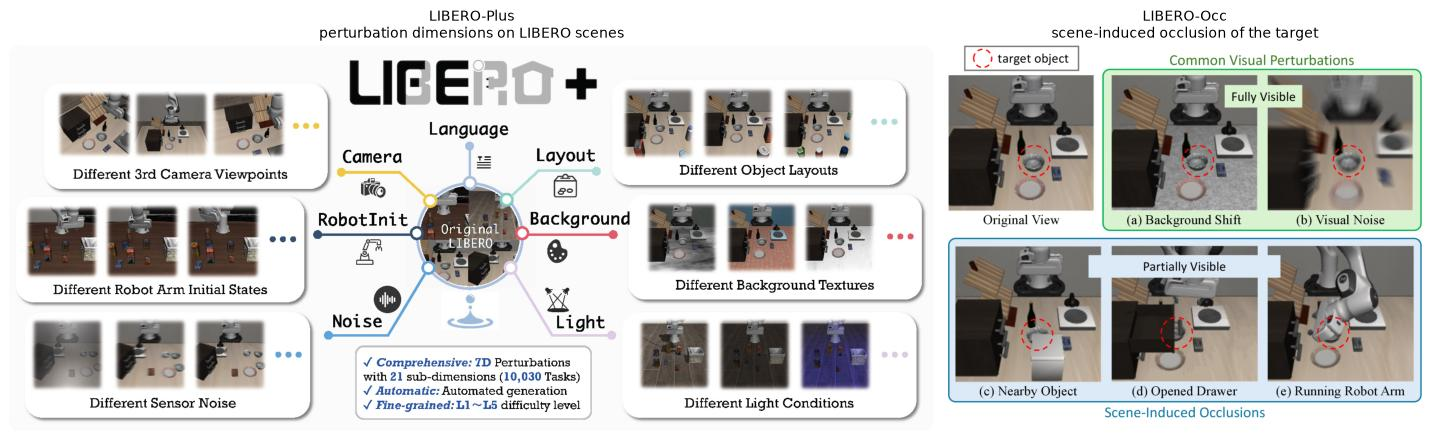

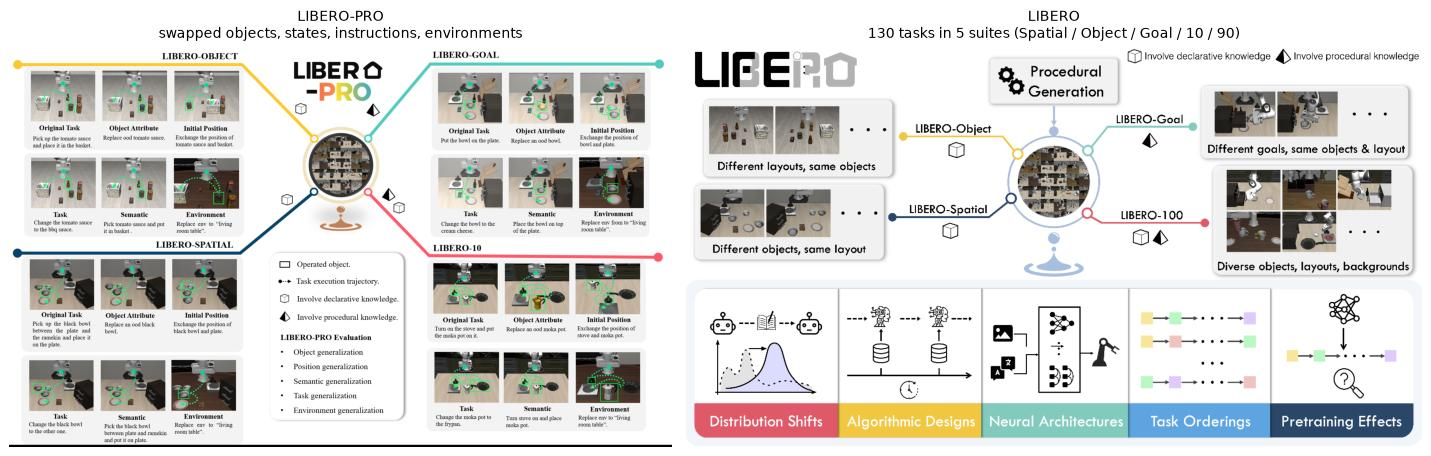

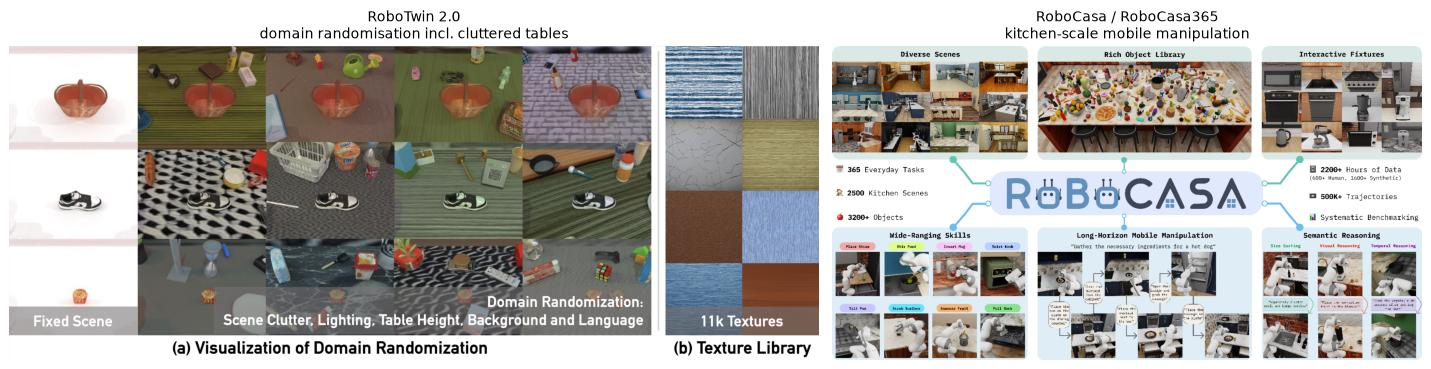

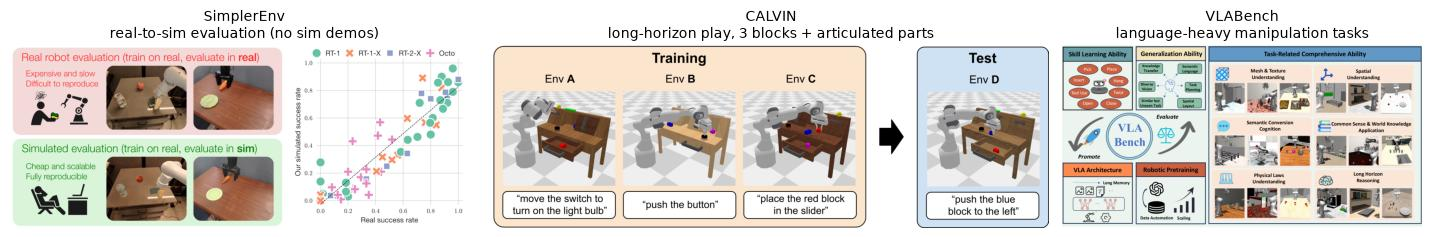

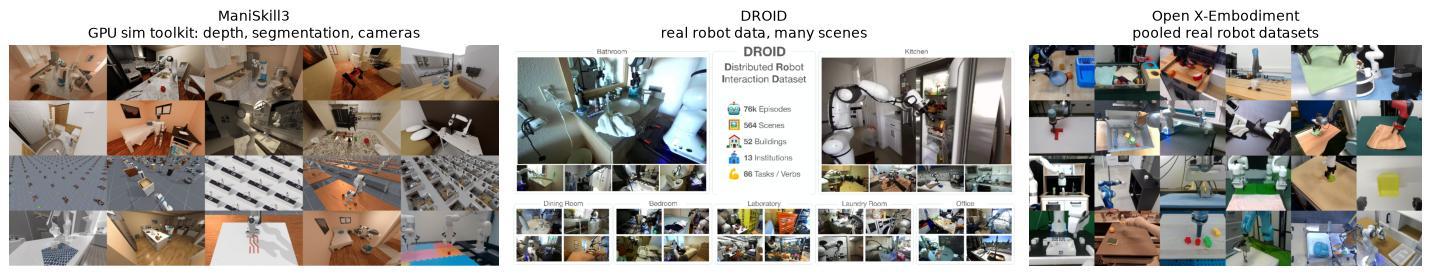

In [3]:
def shrink(path: Path, max_width: int = 1400) -> np.ndarray:
    image = first_frame(path)
    step = max(1, image.shape[1] // max_width)
    return image[::step, ::step]


for row, width in [
    ([(EXT / "libero_plus.jpg", "LIBERO-Plus\nperturbation dimensions on LIBERO scenes"),
      (EXT / "libero_occ.png", "LIBERO-Occ\nscene-induced occlusion of the target")], 16),
    ([(EXT / "libero_pro.png", "LIBERO-PRO\nswapped objects, states, instructions, environments"),
      (EXT / "libero.png", "LIBERO\n130 tasks in 5 suites (Spatial / Object / Goal / 10 / 90)")], 16),
    ([(EXT / "robotwin2_randomization.png", "RoboTwin 2.0\ndomain randomisation incl. cluttered tables"),
      (EXT / "robocasa.webp", "RoboCasa / RoboCasa365\nkitchen-scale mobile manipulation")], 16),
    ([(EXT / "simplerenv.png", "SimplerEnv\nreal-to-sim evaluation (no sim demos)"),
      (EXT / "calvin.png", "CALVIN\nlong-horizon play, 3 blocks + articulated parts"),
      (EXT / "vlabench.png", "VLABench\nlanguage-heavy manipulation tasks")], 16),
    ([(EXT / "maniskill.jpg", "ManiSkill3\nGPU sim toolkit: depth, segmentation, cameras"),
      (EXT / "droid.jpg", "DROID\nreal robot data, many scenes"),
      (EXT / "oxe.png", "Open X-Embodiment\npooled real robot datasets")], 16),
]:
    show_row([(shrink(path), caption) for path, caption in row], width=width, fontsize=11)
plt.show()

<sub>Sources: github.com/sylvestf/LIBERO-plus · arxiv.org/abs/2606.10862 · github.com/Zxy-MLlab/LIBERO-PRO · github.com/Lifelong-Robot-Learning/LIBERO · github.com/RoboTwin-Platform/RoboTwin · github.com/robocasa/robocasa · github.com/simpler-env/SimplerEnv · github.com/mees/calvin · github.com/OpenMOSS/VLABench · github.com/haosulab/ManiSkill · droid-dataset.github.io · github.com/google-deepmind/open_x_embodiment</sub>

## 2 · Where each benchmark enters the plan
> **This section:** which data each pipeline stage (Pipeline v2, V0–V5) uses, and which backbones already have recipes for it.
> **Most promising:** every stage up to V4 stays inside the LIBERO family, so one label pipeline (raw HDF5 → replay) covers the main claim; RoboTwin is needed only at V5.

```text
V0  verify + set up        starVLA + LIBERO, one suite, on 8×A6000             ▶ now
V1  labels                 LIBERO raw HDF5 → affordance, CAW, episode state     (CAW from proprio: section 4)
V2  baseline B0            LIBERO → LIBERO-Plus                                 A6000
V3  CAW + consistency      LIBERO-Plus (B1–B3)                                  A6000
V4  episode state (EAS)    LIBERO-Occ, LIBERO-Plus displacement splits (B4)     A6000
V5  generalise             RoboTwin 2.0 Hard · π0.5 · external baselines        A6000 (+ Isambard)
```

| Backbone | LIBERO (→ Plus / PRO / Occ) | RoboTwin 2.0 | RoboCasa | SimplerEnv |
| --- | --- | --- | --- | --- |
| starVLA · Qwen3-VL-4B + flow head (main) | official recipe | official (50 tasks) | RoboCasa-GR1 | official |
| π0.5 (second backbone) | openpi `pi05_libero` | RoboTwin docs | checkpoint exists | third-party numbers |
| GR00T N1.7 (fallback, ARM) | official | – | recipe | official |

<sub>From the backbone search report (10 Nov); recipes were read from the repositories, nothing has been run yet.</sub>

## 3 · LIBERO-Plus and the diagnostic splits
> **This section:** what the main and diagnostic benchmarks perturb, and what their released data contains.
> **Most promising:** all three are test-only sets, so one model trained on the standard LIBERO demos serves every diagnostic. LIBERO-Plus adds distractors drawn from 416 objects and displaced targets, which map onto the wrong-object and wrong-direction errors we target. On LIBERO-Occ the occluder is present from the first frame, so an episode state can only help once the target comes into view.

| | LIBERO-Plus (main claim) | LIBERO-Occ (diagnostic) | LIBERO-PRO (diagnostic) |
| --- | --- | --- | --- |
| What it changes | 7 dimensions, 21 sub-dimensions, 10,030 tasks, levels L1–L5: camera viewpoint, robot initial state, language, light, background, sensor noise, object layout | the target becomes partly hidden by a nearby object, an opened drawer or the robot's own arm (background shift and visual noise serve as fully visible controls) | objects, initial states, instructions and environments are swapped |
| Released training data | `lerobot/libero_plus`: 14,347 episodes, 2.24 M frames, 40 tasks, 20 fps, 256 × 256 front + wrist video (AV1), 8-D state, 7-D action (checked in `meta/info.json`); **no simulator states, XML, depth or segmentation**, and episodes cannot be mapped back to their BDDL variant (the paper reports > 20,000 trajectories; the release has 14,347). A separate `libero_plus_seg` release (≈ 78 GB, contents not checked) | none. Methods fine-tune on standard LIBERO demos; only BDDL + init files ship for the 2,000 test instances (generation code not released) | none. BDDL + init files per suite and perturbation (HF `zhouxueyang/LIBERO-Pro`, CC-BY-4.0, ≈ 234 kB) |
| Reported results | OpenVLA-OFT fine-tuned on its data 79.6 % (paper); zero-shot ACoT-VLA 86.6 % vs π0.5 85.7 %; best 2026 result 92.4 % (aggregated board) | OpenVLA-OFT 47.95 %, π0 49.30 %, π0.5 40.55 %, VIM 65.05 % | models above 90 % on LIBERO fall to 0 % in the generalised setting |
| Protocol | test-only: train on standard LIBERO, evaluate all 10,030 tasks × 1 trial zero-shot (6 of 7 sampled 2026 papers). Fine-tuning on its data only as an ablation (training camera angles are 5° from the test set) | train on standard LIBERO; test 2,000 instances, 500 per suite (the release defaults to 1 trial per task: set 50). State whether the wrist view is used (VIM 65.05 without, 74.0 with) | evaluation only: 50 episodes per task, max steps 220 / 280 / 300 / 520 |

<sub>From the official figures, the 10 Nov benchmark search and the R2 protocol check (`docs/vla/2026-11-10_VLA_branch_R2_LIBERO变体协议.md`).</sub>

## 4 · One LIBERO-Object task in detail: “pick up the salad dressing and place it in the basket”
> **This section:** what one raw LIBERO task file holds, what the scene looks like, and which CAW labels its proprioception already gives.
> **Most promising:** grasp and release steps fall out of the gripper command, so CAW labels need no simulator. Whether summed actions track the path decides how simple the plan–action consistency loss can be.

LIBERO-Object scenes sit on the floor with several grocery items; only the target and the basket matter for the task, so the rest act as distractors. 50 human teleoperated demos, 20 Hz, 128 × 128 agent-view and wrist cameras. Data Apache-2.0 (HF card), code MIT.

In [4]:
overview = file_overview(TASK_FILE)
info, bddl_name = read_task_info(TASK_FILE)
scene = parse_bddl(TASK_FILE.with_name(Path(bddl_name).name).read_text())  # BDDL fetched with the demo file
print(f"{TASK_FILE.stat().st_size / 1e6:.0f} MB · {overview.attrs['summary']}")
print(f"task: {info.get('language_instruction', scene.language)}")
print(f"objects of interest: {', '.join(scene.of_interest)}")
print(f"distractors ({len(scene.distractors)}): {', '.join(scene.distractors)}")
print(f"goal: {scene.goal}")
overview

664 MB · 50 demos · 6,641 steps · 115–216 steps per demo (mean 133)
task: pick up the salad dressing and place it in the basket
objects of interest: salad_dressing_1, basket_1
distractors (5): ketchup_1, alphabet_soup_1, cream_cheese_1, milk_1, tomato_sauce_1
goal: (And (In salad_dressing_1 basket_1_contain_region))


,shape (demo 0),dtype
key,,
actions,"(137, 7)",float64
dones,"(137,)",uint8
obs/agentview_rgb,"(137, 128, 128, 3)",uint8
obs/ee_ori,"(137, 3)",float64
obs/ee_pos,"(137, 3)",float64
obs/ee_states,"(137, 6)",float64
obs/eye_in_hand_rgb,"(137, 128, 128, 3)",uint8
obs/gripper_states,"(137, 2)",float64
obs/joint_states,"(137, 7)",float64


### Demo 0: key frames around each gripper event

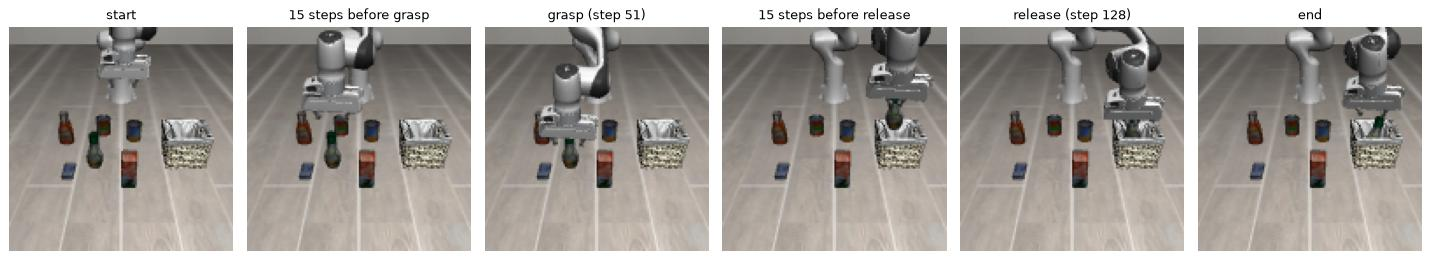

In [5]:
names = list_demos(TASK_FILE)
demo0 = read_demo(TASK_FILE, names[0])
labels0 = caw_labels(demo0.ee_pos, gripper_events(demo0.actions[:, -1]))
show_row(event_frames(demo0, labels0), width=16, fontsize=10)
plt.show()

### Walkthrough: agent view (left) and wrist view (right), with the gripper command and the next event

In [6]:
VIDEO_PATH = ASSETS / "libero_object_salad_dressing_demo0.mp4"
render_demo_video(demo0, labels0, VIDEO_PATH, fps=20)
print(f"{len(demo0.actions)} steps at 20 Hz = {len(demo0.actions) / 20:.1f} s · "
      + ", ".join(f"{'grasp' if lab.event.closing else 'release'} at step {lab.event.step}" for lab in labels0))
Video(str(VIDEO_PATH), embed=True, width=900)

137 steps at 20 Hz = 6.8 s · grasp at step 51, release at step 128


### 3D: end-effector paths of all 50 demos, with demo 0's CAW labels (drag to rotate; click the legend to toggle)

In [7]:
demos = [read_demo(TASK_FILE, name, images=False) for name in names]
labels = [caw_labels(d.ee_pos, gripper_events(d.actions[:, -1])) for d in demos]
path_3d_figure(demos, labels, highlight=0)

### CAW labels across the 50 demos

events per demo: {'1 grasp / 1 release': 44, '2 grasp / 2 release': 5, '1 grasp / 0 release': 1}


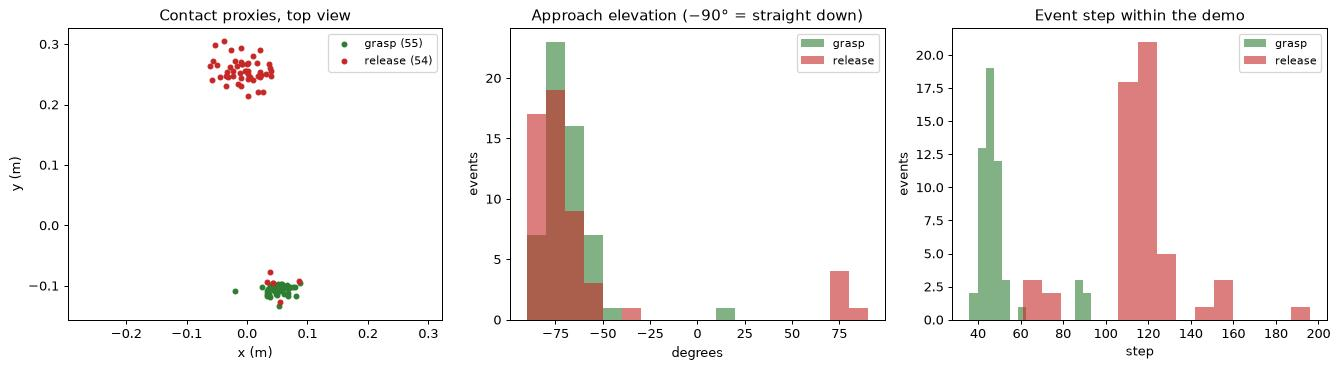

In [8]:
counts = pd.Series([f"{sum(l.event.closing for l in ls)} grasp / {sum(not l.event.closing for l in ls)} release"
                    for ls in labels]).value_counts()
print("events per demo:", {k: int(v) for k, v in counts.items()})
caw_spread_figure(labels)
plt.show()

### Do the summed translation actions reproduce the path? (assumption behind the consistency loss)

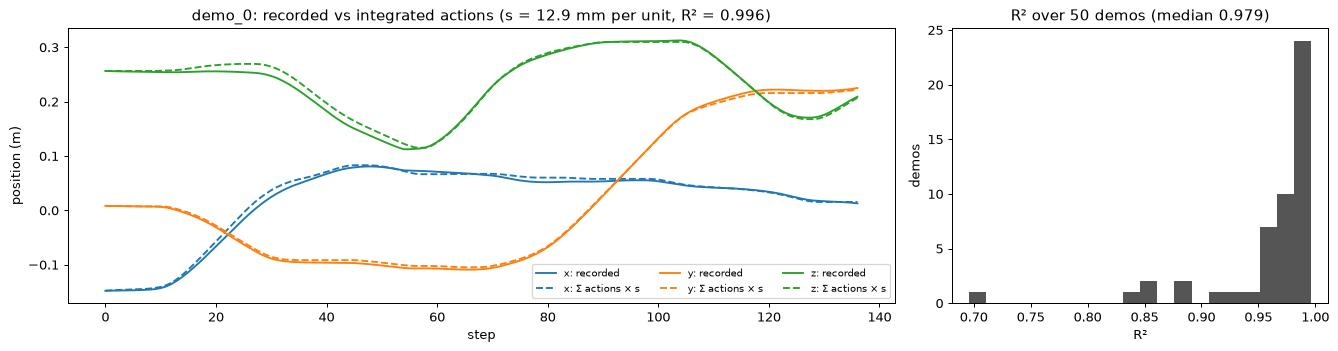

scale s: median 13.01 mm per unit action (IQR 12.90–13.12) · R²: median 0.979, min 0.696


In [9]:
fits = [fit_action_path(d.actions[:, :3], d.ee_pos) for d in demos]
fig = action_fit_figure(demos[0], fits[0], fits)
plt.show()
scales = np.array([f.scale for f in fits]) * 1000
print(f"scale s: median {np.median(scales):.2f} mm per unit action (IQR {np.percentile(scales, 25):.2f}–"
      f"{np.percentile(scales, 75):.2f}) · R²: median {np.median([f.r2 for f in fits]):.3f}, "
      f"min {min(f.r2 for f in fits):.3f}")

### Over one action chunk (16 steps = 0.8 s), how far off is the end point?

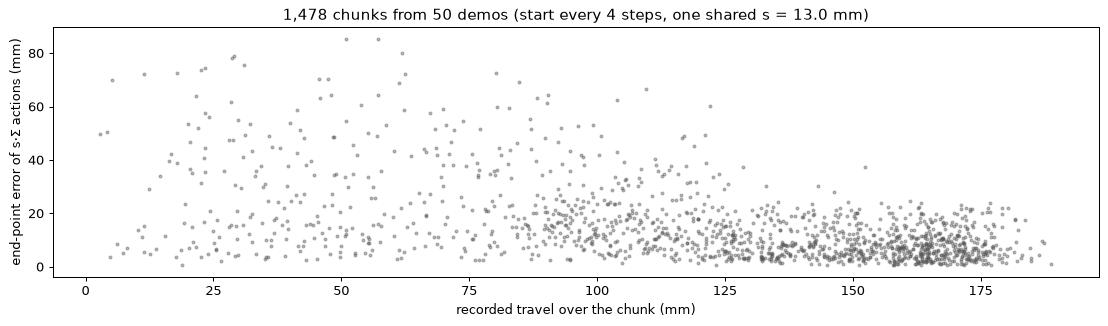

end-point error: median 10.6 mm, 90th percentile 34.3 mm · recorded travel: median 130 mm


In [10]:
scale = float(np.median([f.scale for f in fits]))
chunks = [chunk_endpoint_errors(d.actions[:, :3], d.ee_pos, scale=scale, horizon=16) for d in demos]
errors = np.concatenate([e for e, _ in chunks]) * 1000
travel = np.concatenate([t for _, t in chunks]) * 1000
fig, axis = plt.subplots(figsize=(15, 3.6))
axis.scatter(travel, errors, s=5, alpha=0.4, color="#555")
axis.set(xlabel="recorded travel over the chunk (mm)", ylabel="end-point error of s·Σ actions (mm)",
         title=f"{len(errors):,} chunks from 50 demos (start every 4 steps, one shared s = {scale * 1000:.1f} mm)")
plt.show()
print(f"end-point error: median {np.median(errors):.1f} mm, 90th percentile {np.percentile(errors, 90):.1f} mm "
      f"· recorded travel: median {np.median(travel):.0f} mm")

**Findings**
- **The file can be replayed but has no depth.** Each demo stores RGB from two 128 × 128 cameras, proprioception, 7-D actions, 110-D MuJoCo states and the model XML (`camera_depths` was off at collection). Depth, segmentation and true contacts therefore come from replay in V1, not from the file. The BDDL scene file is not stored and has to be fetched from the LIBERO repository.
- **The scene is genuinely cluttered for this task.** Seven similar-sized grocery items sit on the floor. Only the salad dressing and the basket matter; the other five are distractors, which is where wrong-object errors would come from.
- **The gripper-flip proxy lands where the scene says it should.** Grasps cluster at x ≈ 0.05 m, y ≈ −0.11 m, inside the BDDL `target_object_region` (x 0.025–0.075 m, y −0.125 to −0.075 m). Releases cluster at the basket (`bin_region`, y ≈ 0.26 m). Most grasps come from above (elevation −90° to −50°).
- **Not every demo is one grasp plus one release.** 44 of 50 are. 5 regrasp (two of each), and 1 never reopens the gripper. CAW extraction must allow several segments per demo and cannot assume a fixed count.
- **Summed actions follow the path with one stable scale.** s = 13.0 mm per unit action (IQR 12.9–13.1). That is well below the controller's 50 mm output limit, because the OSC controller does not reach its set-point within one step. Over a whole demo the median R² is 0.979. Over a 16-step chunk the end point is off by ≈ 11 mm (median; 90th percentile ≈ 34 mm) for ≈ 130 mm of travel.
- **The error is not uniform.** It is largest in chunks with little travel: the slow, contact-rich phases around grasp and release. The linear map is weakest exactly where the CAW plan matters most.
- **Implication for the consistency loss:** chunk-relative, soft targets are usable as they are, but they should be down-weighted or replaced near contact. A lag-aware or learned action-to-motion map would tighten them; test that in V3 before fixing the loss.

These are checks of labels and data, not model results.

## 5 · RoboTwin 2.0 Hard: the second benchmark
> **This section:** why the second benchmark is RoboTwin 2.0 in its Hard setting, and what it costs.
> **Most promising:** the official protocol trains on clean demos and tests on randomised, cluttered tables (distractors drawn from 731 objects in 147 categories), and the leaderboard still has a wide gap: π0.5 70.7 % clean / 46.0 % hard against the best entries at 91.8 % / 81.5 %.

| | RoboTwin 2.0 |
| --- | --- |
| Robot | dual-arm Aloha-AgileX (CAW labels per arm) |
| Data | 100k+ trajectories, 50 tasks; HDF5 with converters to LeRobot; MIT licence |
| Labels | flags for depth, point cloud, end-effector pose, mesh / actor segmentation; data re-collected by seed replay |
| Rendering | SAPIEN 3 on Vulkan; needs the Docker graphics capability; stalls reported on A100 / H100 / V100, untested on A6000 |
| Backbones | starVLA official 50-task recipe (48 × A100); π0.5 guide in the RoboTwin docs |

<sub>Leaderboard numbers from robotwin-platform.github.io (official board, 10 Nov); nothing has been downloaded or run.</sub>

## 6 · Not shown yet
- **Depth, instance segmentation and real contacts.** They need MuJoCo replay of the stored states (V1, on the A6000 server). Setting states bypasses dynamics, so contacts need the actions re-executed.
- **LIBERO-Plus, LIBERO-Occ, LIBERO-PRO and RoboTwin data.** None of it has been downloaded yet. The LIBERO-Plus segmentation release alone is ~78 GB.
- **Any model result.** Backbone, protocol and compute checks (R1–R3) are running separately.